# Этап 3. Двумерный анализ (EDA)

**Цель:** понять связи — признаки ↔ SalePrice, признаки ↔ признаки.

**Что смотрим:**
- Корреляции с целевой переменной (Пирсон).
- Scatter plot: ключевые числовые vs SalePrice.
- Boxplot: категориальные vs SalePrice.
- Мультиколлинеарность между признаками.

**Данные:** `data/train_clean.csv`, `data/test_clean.csv` 

In [2]:
import json
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

pd.set_option("display.max_columns", 100) #сколько столбцов pandas будет показывать при выводе DataFrame в ноутбуке
pd.set_option("display.float_format", "{:.2f}".format) # вывод чисел с плавающей точкой -  2 знака после запятой 


sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100 # глобальная плотность пикселей (DPI) для всех фигур matplotlib — 100 точек на дюйм



### Шаг 3.0. Загрузка данных

Используем очищенные данные после этапа 1.

In [5]:
train = pd.read_csv("../data/train_clean.csv")
test  = pd.read_csv("../data/test_clean.csv")

print("train: ", train.shape)
print("test: ", test.shape)
print()

print("Пропусков в train: ", train.isna().sum().sum())
print("Пропусков в test: ", test.isna().sum().sum())
    

train:  (1460, 81)
test:  (1459, 80)

Пропусков в train:  7480
Пропусков в test:  7536


In [7]:
with open("../columns_info.json") as f:
    cols_info = json.load(f)
    
target = cols_info["target"]
pure_num_cols = cols_info["pure_num_cols"]
pseudo_num_cols = cols_info["pseudo_num_cols"]   
cat_cols = cols_info["cat_cols"]   

print(f"Целевая: - {target}")
print(f"Числовых: {len(pure_num_cols)}")
print(f"псевдочисловых: {len(pseudo_num_cols)}")
print(f"Категориальных: {len(cat_cols)}")

Целевая: - SalePrice
Числовых: 33
псевдочисловых: 3
Категориальных: 43


### Шаг 3.1. Корреляции с SalePrice

Считаем корреляцию Пирсона между SalePrice и каждым числовым признаком.
Сортируем — топ-15 положительных и топ-10 отрицательных.


Цель: 
- понять, какие признаки важны для цены 
- понять, как признак влияет на цену 
- отсеять "мусор"

In [9]:
corr_with_target = train.corr(numeric_only = True)[target].sort_values(ascending = False)

print("=== Топ-15 положительных корреляций ===")

print(corr_with_target.head(15).round(3))
print()
print("=== Топ-10 отрицательных корреляций ===")
print(corr_with_target.tail(15).round(3))

=== Топ-15 положительных корреляций ===
SalePrice      1.00
OverallQual    0.79
GrLivArea      0.71
GarageCars     0.64
GarageArea     0.62
TotalBsmtSF    0.61
1stFlrSF       0.61
FullBath       0.56
TotRmsAbvGrd   0.53
YearBuilt      0.52
YearRemodAdd   0.51
MasVnrArea     0.47
Fireplaces     0.47
BsmtFinSF1     0.39
LotFrontage    0.35
Name: SalePrice, dtype: float64

=== Топ-10 отрицательных корреляций ===
BedroomAbvGr     0.17
ScreenPorch      0.11
PoolArea         0.09
MoSold           0.05
3SsnPorch        0.04
BsmtFinSF2      -0.01
BsmtHalfBath    -0.02
MiscVal         -0.02
Id              -0.02
LowQualFinSF    -0.03
YrSold          -0.03
OverallCond     -0.08
MSSubClass      -0.08
EnclosedPorch   -0.13
KitchenAbvGr    -0.14
Name: SalePrice, dtype: float64


#### Вывод:

- OverallQual (0.79) — сильнейшая связь: оценка качества сильно влияет на цену
- GrLivArea (0.71) — жилая площадь: значительно влияет на цену 
- GarageCars (0.64), GarageArea (0.62) — гараж: значительно влияет на цену 
- TotalBsmtSF (0.61), 1stFlrSF (0.61) — площади: значительно влияет на цену 
- YearBuilt (0.52) — год постройки (новые дороже): значительно влияет на цену 

Итого: наиболее сильно на цену влияют показатели качество, площадь, гараж, возраст

###  Шаг 3.2. Heatmap корреляций топ-признаков

Строим heatmap для топ-15 признаков по корреляции с целевой.
Ищем мультиколлинеарность (корреляции между признаками).

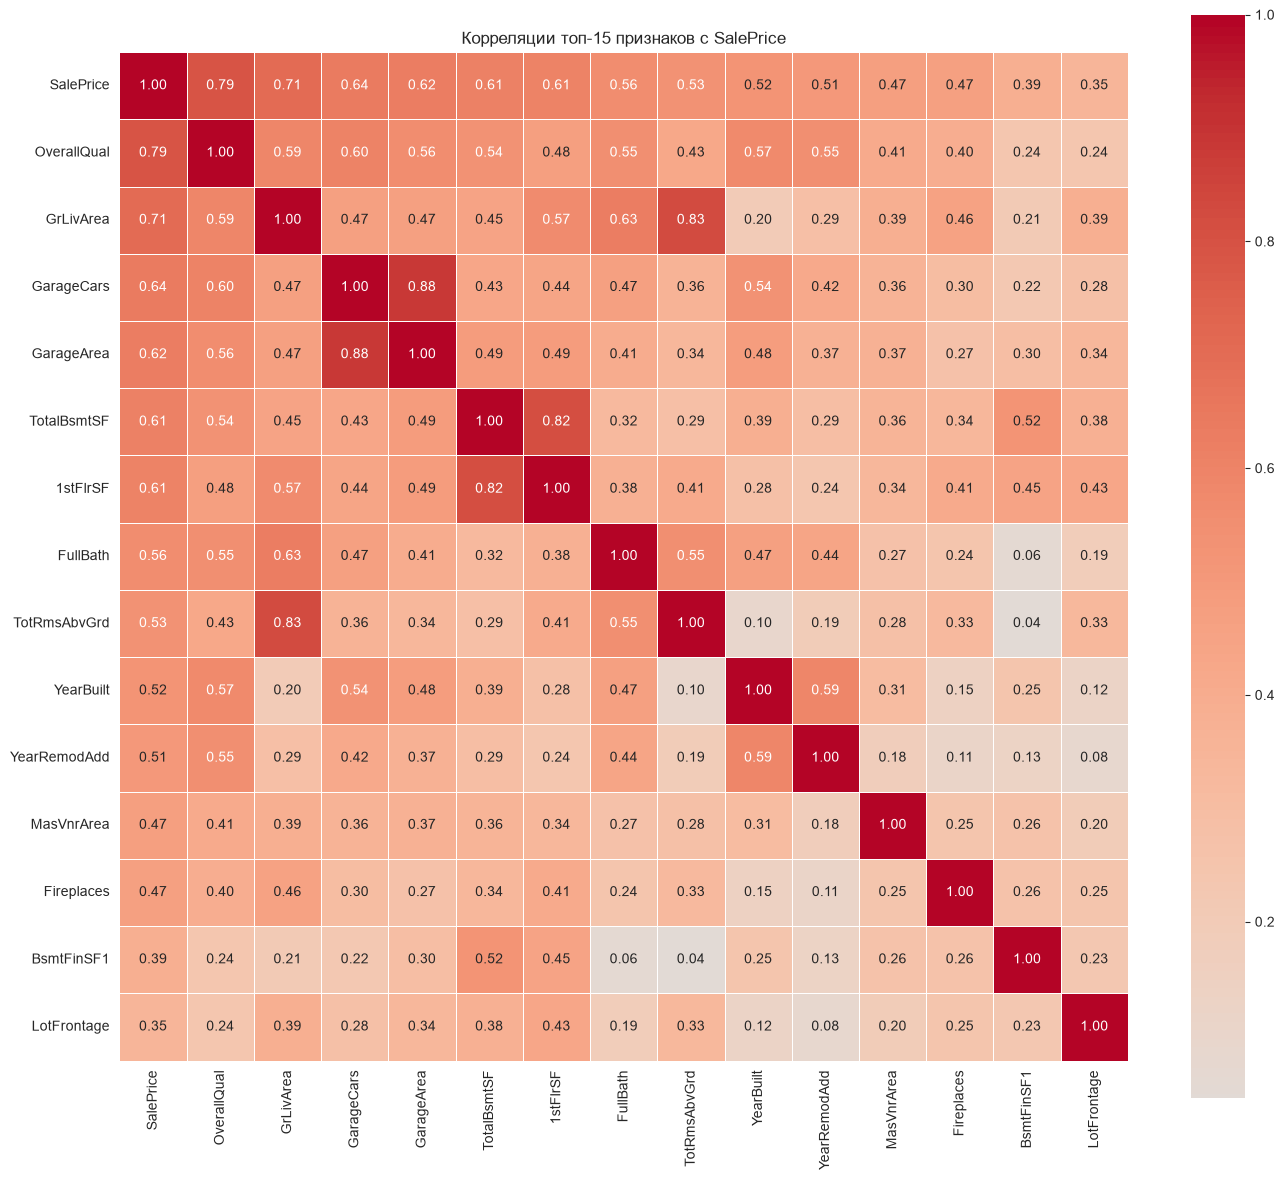

In [13]:
top_features = corr_with_target.head(15).index.tolist()
plt.figure(figsize= (14, 12))

sns.heatmap(
    train[top_features].corr(), 
    annot = True, 
    fmt = ".2f", 
    cmap = "coolwarm", 
    center = 0, 
    square = True, 
    linewidth = 0.5
)

plt.title("Корреляции топ-15 признаков с SalePrice")
plt.tight_layout()
plt.show()

#### Выводы 

- OverallQual — 0.79 — сильнейшая связь.
- GrLivArea — 0.71 — жилая площадь.
- GarageCars — 0.64, GarageArea — 0.62 — гараж.
- TotalBsmtSF — 0.61, 1stFlrSF — 0.61 — площади подвала и 1-го этажа.
- FullBath — 0.56 — число ванных.
- TotRmsAbvGrd — 0.53 — число комнат.
- YearBuilt — 0.52, YearRemodAdd — 0.51 — год постройки и ремонта.


- GarageCars ↔ GarageArea = 0.88 — сильно коррелируют.
- GrLivArea ↔ TotRmsAbvGrd = 0.83 — связаны.
- TotalBsmtSF ↔ 1stFlrSF = 0.82 — обе про площадь.
- YearBuilt ↔ YearRemodAdd = 0.59 — год постройки и ремонт.

Мультиколлинеарность — признаки дублируют друг друга.

### Шаг 3.3. Scatter plot: ключевые числовые vs SalePrice

Строим scatter plot для 3 сильнейших признаков — видим форму связи.

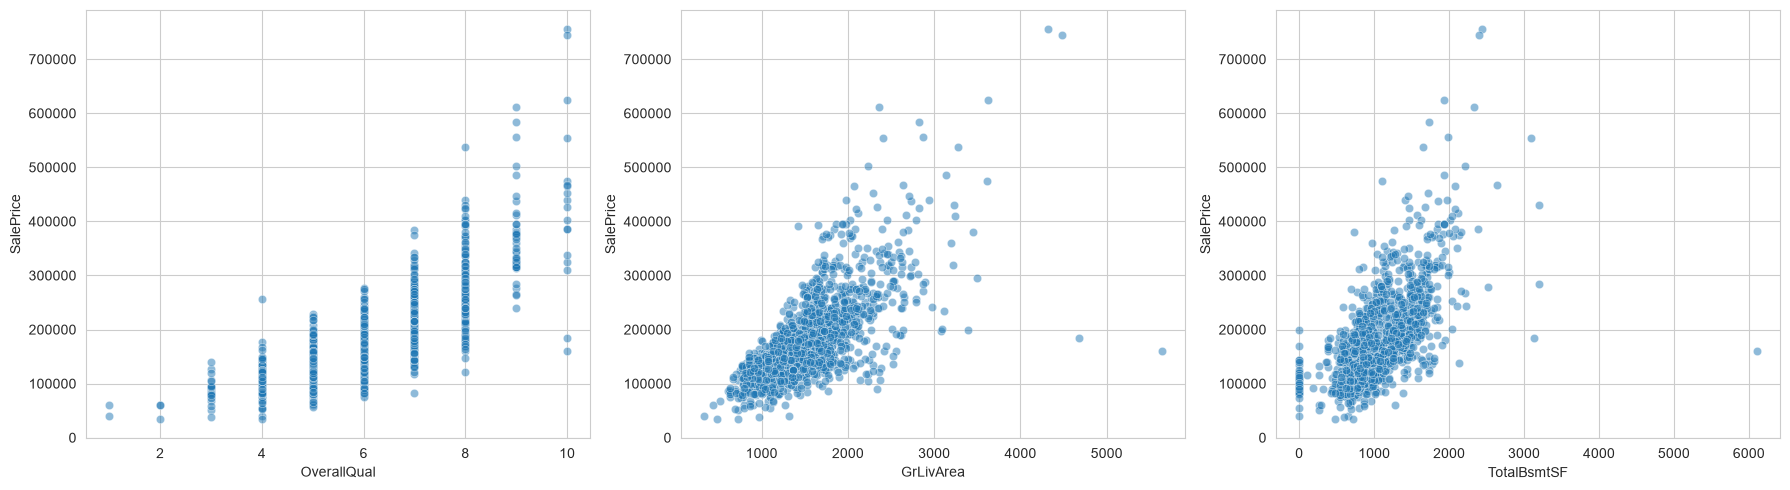

In [16]:
fig, axes = plt.subplots(1, 3, figsize= (18,5))
top3 = ["OverallQual", "GrLivArea", "TotalBsmtSF"]

for ax, col in zip(axes, top3):
    sns.scatterplot(data= train, x = col, y=  target, alpha = 0.5, ax= ax)
    ax.set_title = (f"{col} vs SalePrice")
    
    
plt.tight_layout()
plt.show()

### Вывод: 

OverallQual — ступенчатая связь:  заметный скачок цены.

GrLivArea — почти линейная связь, но с большим разбросом.

TotalBsmtSF —  почти линейная связь.

### Шаг 3.4. Boxplot: категориальные vs SalePrice

Строим boxplot для ключевых категориальных — как цены различаются по категориям.

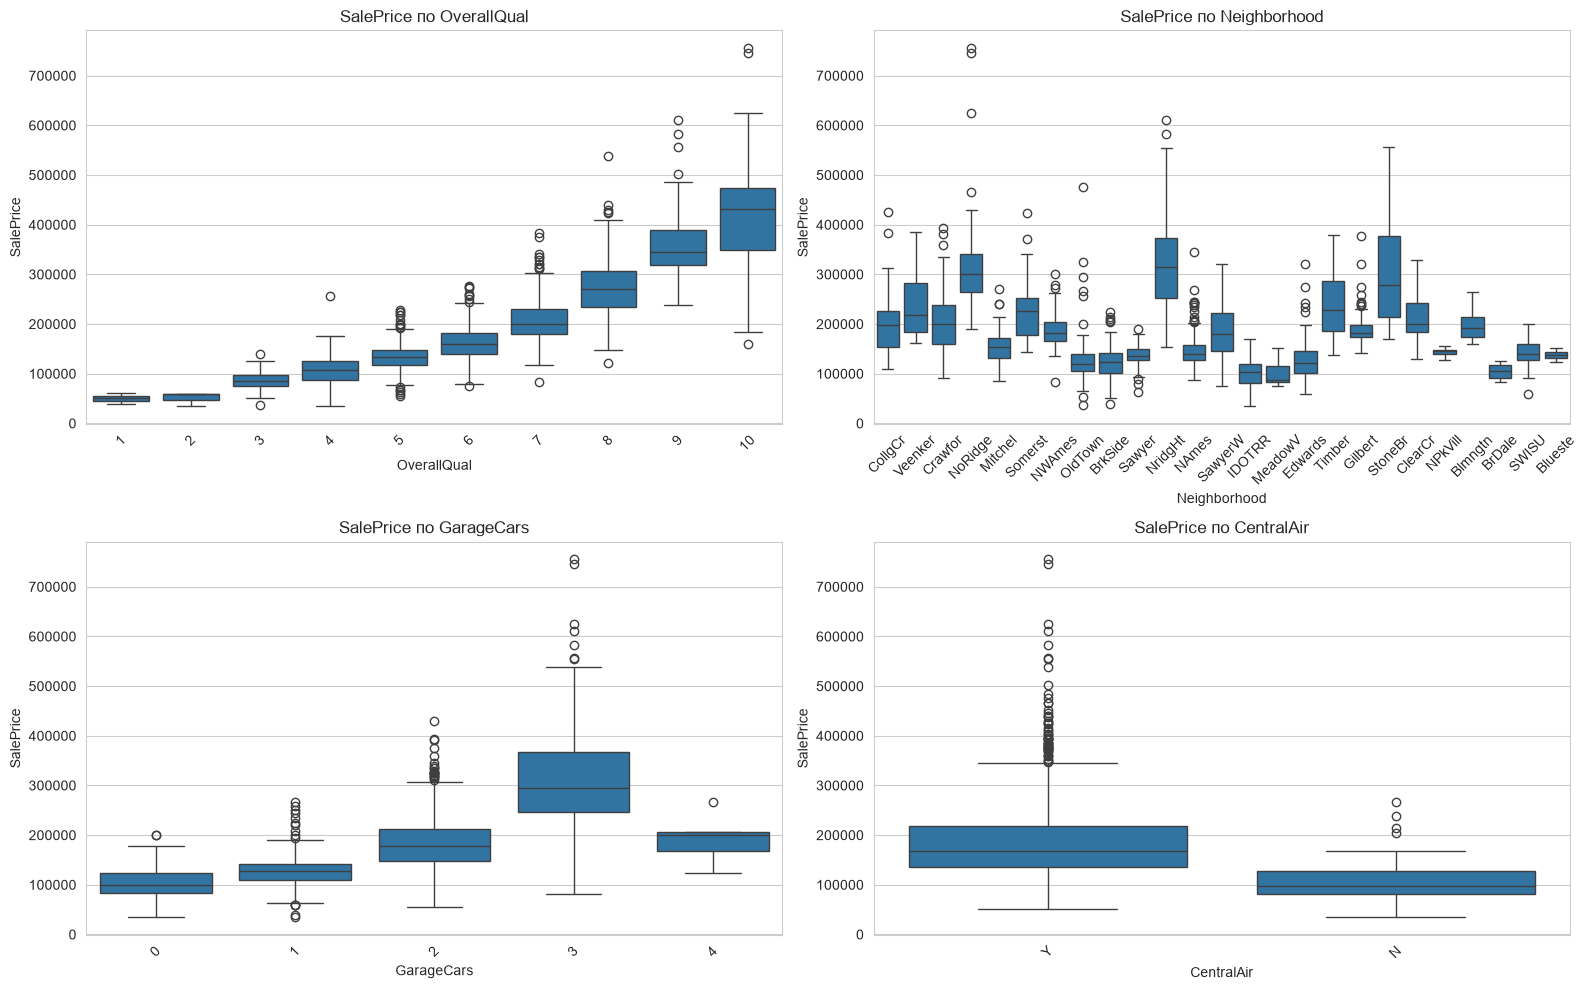

In [17]:
fig, axes = plt.subplots(2, 2, figsize = (16, 10))


key_cats = ["OverallQual", "Neighborhood", "GarageCars", "CentralAir"]

for ax, col in zip(axes.ravel(), key_cats):
    sns.boxplot(data = train, x = col, y = target, ax= ax)
    ax.set_title(f"SalePrice по {col}")
    ax.tick_params(axis = "x", rotation = 45)
    
plt.tight_layout()
plt.show()

#### Выводы 

OverallQual — ступенчатый рост: с качеством растёт цена.

Neighborhood — сильный разброс по районам.

GarageCars — с числом мест в гараже растёт цена.

CentralAir — дома с кондиционером (Y) дороже, чем без (N).

OverallQual, Neighborhood, GrLivArea —   сильнее всего влияют на цену.

**OverallQual** — ступенчатый рост: каждый +1 к оценке → +$40–70k к медиане. Разница между 1 и 10 — почти в 10 раз. Сильнейший признак.

**Neighborhood** — разброс до 4 раз между районами. Топ: NoRidge, NridgHt, StoneBr (~300k). Низ: MeadowV, IDOTRR, BrDale (~80–110k).

**GarageCars** — с ростом числа мест растёт цена. Но 4 машины — редкий случай.

**CentralAir** — дома с кондиционером (Y) дороже на ~$60k. Бинарный, но важный.

**Выбросы:** в каждом boxplot видны кружки — реальные дорогие/дешёвые дома. На этапе 4 будем их анализировать.




In [19]:
neighborhood_stats = train.groupby("Neighborhood")[target].agg(
    ["count", "mean", "median"]
).sort_values("median", ascending=False).round(0)
neighborhood_stats
print("=== Топ-10 самых дорогих районов ===")
print(neighborhood_stats.head(10))
print()
print("=== Топ-10 самых дешёвых ===")
print(neighborhood_stats.tail(10))
 

=== Топ-10 самых дорогих районов ===
              count      mean    median
Neighborhood                           
NridgHt          77 316271.00 315000.00
NoRidge          41 335295.00 301500.00
StoneBr          25 310499.00 278000.00
Timber           38 242247.00 228475.00
Somerst          86 225380.00 225500.00
Veenker          11 238773.00 218000.00
Crawfor          51 210625.00 200624.00
ClearCr          28 212565.00 200250.00
CollgCr         150 197966.00 197200.00
Blmngtn          17 194871.00 191000.00

=== Топ-10 самых дешёвых ===
              count      mean    median
Neighborhood                           
NAmes           225 145847.00 140000.00
SWISU            25 142591.00 139500.00
Blueste           2 137500.00 137500.00
Sawyer           74 136793.00 135000.00
BrkSide          58 124834.00 124300.00
Edwards         100 128220.00 121750.00
OldTown         113 128225.00 119000.00
BrDale           16 104494.00 106000.00
IDOTRR           37 100124.00 103000.00
MeadowV      

#### Вывод:

NoRidge — $301k (самый дорогой).
MeadowV — $88k (самый дешёвый).

In [ ]:
corr_matrix = train[pure_num_cols].corr() # построение матрицы корреляции только для числовых признаков 
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k = 1) # построение булевой матрицы, True ставится только выше главной диагонали 
high_corr = corr_matrix.where(mask).stack().reset_index() # .where(mask) — оставляет значения там, где mask = True, остальные заменяет на NaN.
# .stack() — «расплющивает» матрицу в Series: было 33×33 → стало ~528 пар (все True-ячейки), а NaN (нижний треугольник + диагональ) отбрасываются автоматически.
# .reset_index() — превращает индекс (row, col) обратно в два столбца level_0, level_1, 0.
high_corr.columns = ["feature_1", "feature_2", "corr"]
high_corr = high_corr[high_corr["corr"].abs() > 0.8] # оставляет только пары, где модуль корреляции > 0.8.
high_corr = high_corr.sort_values("corr", ascending=False, key=abs) #сортирует пары по модулю корреляции, от большего к меньшему
# key=abs: сначала самые сильные связи, независимо от знака (−0.9 тоже попадает в топ)

print(f"Пар с корреляцией > 0.8: {len(high_corr)}")
print()
print(high_corr.round(3))


Пар с корреляцией > 0.8: 3

       feature_1     feature_2  corr
817   GarageCars    GarageArea  0.88
483    GrLivArea  TotRmsAbvGrd  0.82
341  TotalBsmtSF      1stFlrSF  0.82


## Итог по этапу 3

#### Корреляции с SalePrice (числовые)

**Топ-5 признаков:**
1. `OverallQual` — 0.79
2. `GrLivArea` — 0.71
3. `GarageCars` — 0.64
4. `GarageArea` — 0.62
5. `TotalBsmtSF` — 0.61

Сильнее всего на цену дома влияют качество дома, жилая площадь, гараж и площадь подвала 

#### Ключевые связи (визуально)
- `OverallQual` — ступенчатая связь (каждый +1 балл → заметный скачок цены).
- `GrLivArea` — почти линейная.
- `TotalBsmtSF` — почти линейная.

#### Категориальные признаки (boxplot, groupby)
- `Neighborhood` — разница между районами до 4 раз ($88k vs $301k).
- `OverallQual` — ступенчатый рост цены.
- `GarageCars` — с числом мест в гараже растёт цена.
- `CentralAir` — дома с кондиционером дороже на ~$60k.

#### Мультиколлинеарность
Найдено **3 пары** с корреляцией > 0.8:
- `GarageCars` ↔ `GarageArea` (0.88) — число мест и площадь гаража.
- `GrLivArea` ↔ `TotRmsAbvGrd` (0.82) — площадь и число комнат.
- `TotalBsmtSF` ↔ `1stFlrSF` (0.82) — площадь подвала и 1-го этажа.
